# Figure 4: Carbon intensity and manufacturing-emission payback

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [11]:
df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Carbon Intensity",
)

In [12]:
# ---
# Materials carbon intensity
# ---

# Technology columns
tech_cols = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydro",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Solar Thermal",
    "Wind Onshore",
    "Wind Offshore",
]

# Aggregate by material group and convert to tCO2/MW
df_grouped = (
    df.groupby("Group")[tech_cols]
    .sum()
    / 1000
)

df_grouped = df_grouped.rename(
    columns={
        "Hydro": "Hydropower",
    }
)

# Transpose for plotting
df_plot = df_grouped.T

# Technology order
order = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydropower",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Solar Thermal",
    "Wind Onshore",
    "Wind Offshore",
]

df_plot = df_plot.reindex(order)

# Replace missing values with zero
df_plot = df_plot.fillna(0)

In [13]:
# ---
# Style
# ---

# Same font sizes for panels a and b
FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_TECH = 10.0
FONT_GROUP = 10.5
FONT_SCENARIO = 10.0
FONT_TOTAL = 10.0
FONT_MANUFACTURING_LABEL = 10.0
FONT_AXIS_LABEL = 11.5
FONT_LEGEND = 10.0
FONT_PANEL_LABEL = 11.5

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.70,
        "axes.labelsize": FONT_AXIS_LABEL,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TECH,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Colours
# ---

COLOR_MANUFACTURING = "#4F9AB8"
COLOR_FUEL = "#B94745"
COLOR_GRID = "#BFBFBF"
COLOR_TEXT = "#222222"
COLOR_SECONDARY_TEXT = "#555555"
COLOR_BACKGROUND = "white"
COLOR_AXIS = "#444444"
COLOR_GROUP_LINE = "#777777"

In [14]:
# ---
# Configuration
# ---

technology_col = "Technology"
CARBON_THRESHOLD = 25.0  # gCO2/kWh


# ---
# Technology groups - panel a
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
        "Solar Thermal",
    ],
}

In [15]:
# ---
# Prepare input
# ---

df_capacity = df_plot.copy()

if technology_col in df_capacity.columns:
    df_capacity = df_capacity.set_index(
        technology_col,
    )

# Harmonise naming
df_capacity = df_capacity.rename(
    index={
        "Hydro": "Hydropower",
    }
)

# Aggregate duplicate technologies if required
df_capacity = (
    df_capacity
    .groupby(df_capacity.index)
    .sum(numeric_only=True)
)


# ---
# Full technology set
# ---

all_techs = [
    tech
    for group in tech_groups.values()
    for tech in group
]

df_capacity = df_capacity.reindex(
    all_techs,
)

# Total manufacturing footprint in tCO2e/MW installed
capacity_input = df_capacity.sum(
    axis=1,
)


# ---
# Fuel footprint
# ---

# Fuel footprint in gCO2e/kWh electricity
fuel_footprint = {
    "Bioenergy": 12 / 0.38,
    "Coal": 317 / 0.44,
    "Geothermal": 0,
    "Hydropower": 0,
    "Natural Gas": 182 / 0.55,
    "Nuclear": 3,
    "Oil": 267 / 0.32,
    "Solar PV": 0,
    "Solar Thermal": 0,
    "Wind Onshore": 0,
    "Wind Offshore": 0,
}

fuel_series = (
    pd.Series(fuel_footprint)
    .reindex(all_techs)
    .fillna(0)
)


# ---
# Capacity factors
# ---

capacity_factor_dict = {
    "Bioenergy": {
        "low": 0.636,
        "mean": 0.636,
        "high": 0.636,
    },
    "Coal": {
        "low": 0.600,
        "mean": 0.600,
        "high": 0.600,
    },
    "Geothermal": {
        "low": 0.838,
        "mean": 0.838,
        "high": 0.838,
    },
    "Hydropower": {
        "low": 0.451,
        "mean": 0.451,
        "high": 0.451,
    },
    "Natural Gas": {
        "low": 0.633,
        "mean": 0.633,
        "high": 0.633,
    },
    "Nuclear": {
        "low": 0.817,
        "mean": 0.817,
        "high": 0.817,
    },
    "Oil": {
        "low": 0.263,
        "mean": 0.263,
        "high": 0.263,
    },
    "Solar PV": {
        "low": 0.200,
        "mean": 0.200,
        "high": 0.200,
    },
    "Solar Thermal": {
        "low": 0.420,
        "mean": 0.420,
        "high": 0.420,
    },
    "Wind Onshore": {
        "low": 0.338,
        "mean": 0.338,
        "high": 0.338,
    },
    "Wind Offshore": {
        "low": 0.421,
        "mean": 0.421,
        "high": 0.421,
    },
}


# ---
# Lifespans
# ---

lifespan_dict = {
    "Bioenergy": {
        "low": 10,
        "mean": 17,
        "high": 47,
    },
    "Coal": {
        "low": 46,
        "mean": 56,
        "high": 66,
    },
    "Geothermal": {
        "low": 17,
        "mean": 23,
        "high": 30,
    },
    "Hydropower": {
        "low": 34,
        "mean": 86,
        "high": 110,
    },
    "Natural Gas": {
        "low": 25,
        "mean": 44,
        "high": 62,
    },
    "Nuclear": {
        "low": 16,
        "mean": 31,
        "high": 45,
    },
    "Oil": {
        "low": 20,
        "mean": 41,
        "high": 63,
    },
    "Solar PV": {
        "low": 7,
        "mean": 8,
        "high": 13,
    },
    "Solar Thermal": {
        "low": 5,
        "mean": 31,
        "high": 35,
    },
    "Wind Onshore": {
        "low": 10,
        "mean": 15,
        "high": 24,
    },
    "Wind Offshore": {
        "low": 18,
        "mean": 22,
        "high": 26,
    },
}


# ---
# Build capacity-factor series
# ---

cf_low = pd.Series(
    {
        key: values["low"]
        for key, values in capacity_factor_dict.items()
    }
).reindex(all_techs)

cf_mean = pd.Series(
    {
        key: values["mean"]
        for key, values in capacity_factor_dict.items()
    }
).reindex(all_techs)

cf_high = pd.Series(
    {
        key: values["high"]
        for key, values in capacity_factor_dict.items()
    }
).reindex(all_techs)


# ---
# Build lifespan series
# ---

life_low = pd.Series(
    {
        key: values["low"]
        for key, values in lifespan_dict.items()
    }
).reindex(all_techs)

life_mean = pd.Series(
    {
        key: values["mean"]
        for key, values in lifespan_dict.items()
    }
).reindex(all_techs)

life_high = pd.Series(
    {
        key: values["high"]
        for key, values in lifespan_dict.items()
    }
).reindex(all_techs)

In [16]:
# ---
# Panel a - manufacturing intensity
# ---

# gCO2e/kWh =
# 1000 * tCO2e/MW / (CF * 8760 * lifespan)

conv_L = 1000 / (
    cf_low
    * 8760
    * life_low
)

conv_M = 1000 / (
    cf_mean
    * 8760
    * life_mean
)

conv_H = 1000 / (
    cf_high
    * 8760
    * life_high
)

manufacturing_L = (
    capacity_input
    * conv_L
)

manufacturing_M = (
    capacity_input
    * conv_M
)

manufacturing_H = (
    capacity_input
    * conv_H
)


# ---
# Panel a - build dataframe
# ---

scenario_labels = [
    "80",
    "50",
    "10",
]

df_scenarios = pd.DataFrame(
    {
        ("80", "Manufacturing"): manufacturing_L,
        ("80", "Fuel"): fuel_series,
        ("50", "Manufacturing"): manufacturing_M,
        ("50", "Fuel"): fuel_series,
        ("10", "Manufacturing"): manufacturing_H,
        ("10", "Fuel"): fuel_series,
    }
).reindex(all_techs)


# ---
# Panel a - order within groups
# ---

# Order using central 50% total intensity
total_50 = (
    df_scenarios[("50", "Manufacturing")]
    + df_scenarios[("50", "Fuel")]
)

ordered_groups = {}

for group_name, group_techs in tech_groups.items():
    available = [
        tech
        for tech in group_techs
        if tech in df_scenarios.index
    ]

    ordered_groups[group_name] = sorted(
        available,
        key=lambda tech: total_50.loc[tech],
        reverse=True,
    )



In [17]:
# ---
# Panel b - technology groups
# ---

tech_groups_b = {
    "Fossil fuels": [
        "Oil",
        "Coal",
        "Natural Gas",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Solar Thermal",
        "Geothermal",
        "Hydropower",
    ],
}

tech_order_b = [
    tech
    for group in tech_groups_b.values()
    for tech in group
]


# ---
# Panel b - capacity factors
# ---

# Use the same capacity factors as panel a
typical_cf_b = cf_mean.reindex(
    tech_order_b,
)


# ---
# Panel b - manufacturing footprint
# ---

E_man_b = (
    pd.Series(capacity_input)
    .reindex(tech_order_b)
    .astype(float)
)

if E_man_b.isna().any():
    missing = (
        E_man_b[
            E_man_b.isna()
        ]
        .index
        .tolist()
    )

    raise ValueError(
        "Missing manufacturing footprint for: "
        + ", ".join(missing)
    )


# ---
# Panel b - threshold calculation
# ---

# Electricity generated per MW installed
generation_required_kwh_b = (
    E_man_b
    * 1_000_000
    / CARBON_THRESHOLD
)

# 1 million kWh = 1 GWh
generation_required_mkwh_b = (
    generation_required_kwh_b
    / 1_000_000
)


# ---
# Panel b - equivalent operating years
# ---

years_required_b = (
    generation_required_kwh_b
    / (
        1000
        * 8760
        * typical_cf_b
    )
)

df_panel_b = pd.DataFrame(
    {
        "Manufacturing footprint (tCO2/MW)": E_man_b,
        "Typical capacity factor": typical_cf_b,
        "Generation required (kWh/MW)": generation_required_kwh_b,
        "Generation required (GWh/MW)": generation_required_mkwh_b,
        "Years of typical operation": years_required_b,
    }
)


# ---
# Panel a - grouped y positions
# ---

BAR_HEIGHT = 0.32

scenario_offsets = {
    "80": -0.36,
    "50": 0.00,
    "10": 0.36,
}

TECH_SPACING = 1.20
GROUP_GAP = 0.75

y_positions = {}
group_header_positions = {}
group_line_positions = {}

current_y = 0.0

for group_name, techs in ordered_groups.items():
    if len(techs) == 0:
        continue

    first_y = current_y

    group_header_positions[group_name] = (
        first_y - 0.95
    )

    group_line_positions[group_name] = (
        first_y - 0.68
    )

    for tech in techs:
        y_positions[tech] = current_y
        current_y += TECH_SPACING

    current_y += GROUP_GAP

ordered_techs = [
    tech
    for group_name in ordered_groups
    for tech in ordered_groups[group_name]
]

df_scenarios = df_scenarios.reindex(
    ordered_techs,
)


# ---
# Panel a - broken x axis
# ---

X_LEFT_MAX = 100
X_RIGHT_MIN = 300
X_RIGHT_MAX = 850
X_LABEL_PAD = 13



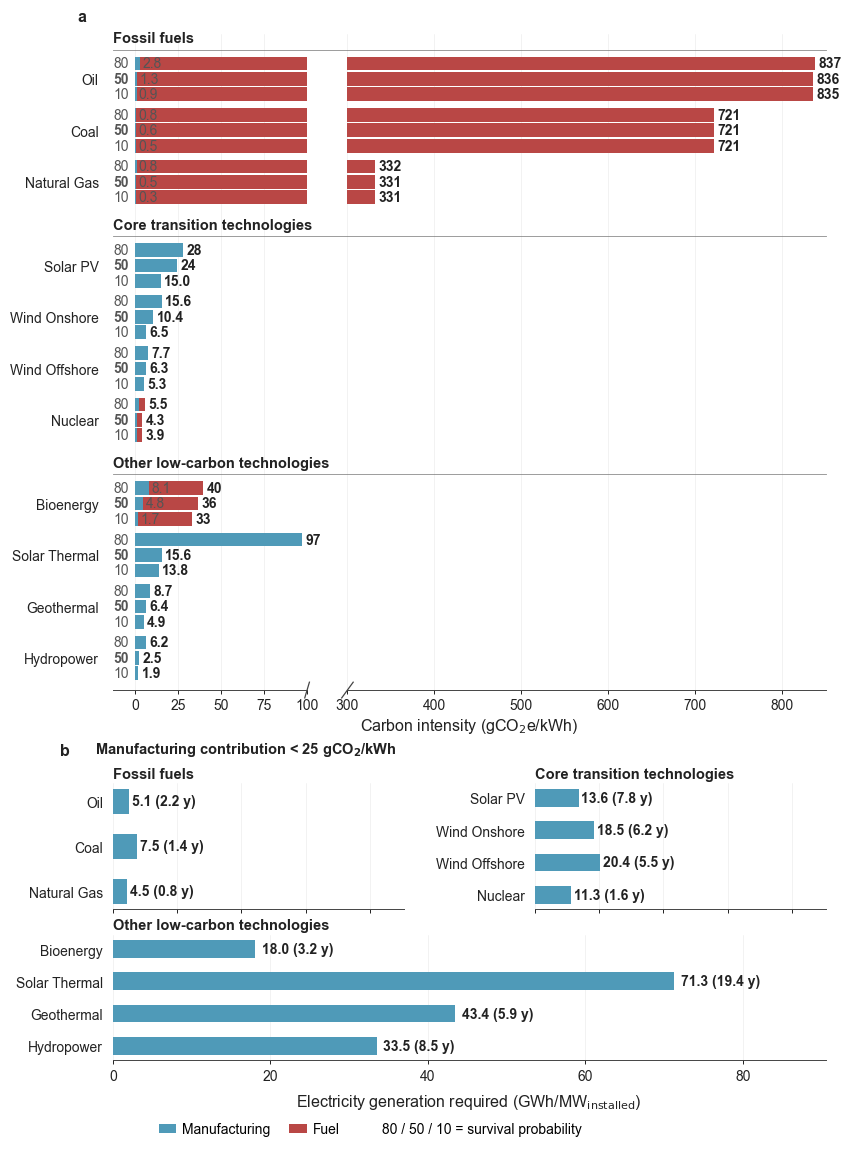

In [18]:
# ---
# Complete figure
# ---

# Panel b receives less vertical space while retaining
# the same font sizes as panel a.
fig = plt.figure(
    figsize=(9.2, 11.8),
    facecolor=COLOR_BACKGROUND,
)

outer = fig.add_gridspec(
    2,
    1,
    height_ratios=[
        2.25,
        0.95,
    ],
    hspace=0.2,
)


# ---
# Panel a - broken axis
# ---

gs_a = outer[0].subgridspec(
    1,
    2,
    width_ratios=[
        1.30,
        3.20,
    ],
    wspace=0.12,
)

ax_left = fig.add_subplot(
    gs_a[0, 0],
)

ax_right = fig.add_subplot(
    gs_a[0, 1],
    sharey=ax_left,
)


# ---
# Panel b - compact layout
# ---

gs_b = outer[1].subgridspec(
    2,
    2,
    height_ratios=[
        1.0,
        1.0,
    ],
    hspace=0.2,
    wspace=0.45,
)

ax_fossil = fig.add_subplot(
    gs_b[0, 0],
)

ax_core = fig.add_subplot(
    gs_b[0, 1],
)

ax_other = fig.add_subplot(
    gs_b[1, :],
)

for ax in [
    ax_left,
    ax_right,
    ax_fossil,
    ax_core,
    ax_other,
]:
    ax.set_facecolor(
        COLOR_BACKGROUND,
    )


# ---
# Panel a - group headings
# ---

for group_name in ordered_groups:
    if group_name not in group_header_positions:
        continue

    ax_left.text(
        0.0,
        group_header_positions[group_name],
        group_name,
        transform=ax_left.get_yaxis_transform(),
        ha="left",
        va="center",
        fontsize=FONT_GROUP,
        fontweight="bold",
        color=COLOR_TEXT,
        clip_on=False,
        zorder=6,
    )


# ---
# Panel a - bars
# ---

for tech in ordered_techs:
    y_center = y_positions[tech]

    for scen in scenario_labels:
        y = (
            y_center
            + scenario_offsets[scen]
        )

        manufacturing_value = df_scenarios.loc[
            tech,
            (
                scen,
                "Manufacturing",
            ),
        ]

        fuel_value = df_scenarios.loc[
            tech,
            (
                scen,
                "Fuel",
            ),
        ]

        total_value = (
            manufacturing_value
            + fuel_value
        )

        # Bars on both broken axes
        for ax in [
            ax_left,
            ax_right,
        ]:
            # Manufacturing
            ax.barh(
                y,
                manufacturing_value,
                height=BAR_HEIGHT,
                color=COLOR_MANUFACTURING,
                edgecolor="none",
                zorder=3,
            )

            # Fuel
            ax.barh(
                y,
                fuel_value,
                left=manufacturing_value,
                height=BAR_HEIGHT,
                color=COLOR_FUEL,
                edgecolor="none",
                zorder=3,
            )

        # Survival probability label
        ax_left.text(
            -3.5,
            y,
            scen,
            va="center",
            ha="right",
            fontsize=FONT_SCENARIO,
            fontweight=(
                "bold"
                if scen == "50"
                else "normal"
            ),
            color=COLOR_SECONDARY_TEXT,
            zorder=5,
            clip_on=False,
        )

        # Total intensity label
        if np.isfinite(total_value):
            total_label = (
                f"{int(round(total_value))}"
                if total_value >= 20
                else f"{total_value:.1f}"
            )

            if total_value <= X_LEFT_MAX:
                ax_label = ax_left
                x_label = total_value + 2.0

            elif total_value >= X_RIGHT_MIN:
                ax_label = ax_right
                x_label = total_value + 4.0

            else:
                ax_label = ax_left
                x_label = X_LEFT_MAX - 3

            ax_label.text(
                x_label,
                y,
                total_label,
                va="center",
                ha="left",
                fontsize=FONT_TOTAL,
                fontweight="bold",
                color=COLOR_TEXT,
                zorder=5,
                clip_on=False,
            )

        # Manufacturing-only label
        if (
            tech in [
                "Bioenergy",
                "Coal",
                "Natural Gas",
                "Oil",
            ]
            and np.isfinite(manufacturing_value)
        ):
            manufacturing_label = (
                f"{int(round(manufacturing_value))}"
                if manufacturing_value >= 10
                else f"{manufacturing_value:.1f}"
            )

            if manufacturing_value <= X_LEFT_MAX:
                ax_m = ax_left
                x_m = manufacturing_value + 1.3

            elif manufacturing_value >= X_RIGHT_MIN:
                ax_m = ax_right
                x_m = manufacturing_value + 2.2

            else:
                ax_m = ax_left
                x_m = X_LEFT_MAX - 4

            ax_m.text(
                x_m,
                y,
                manufacturing_label,
                va="center",
                ha="left",
                fontsize=FONT_MANUFACTURING_LABEL,
                fontweight="normal",
                color=COLOR_SECONDARY_TEXT,
                zorder=6,
                clip_on=False,
            )


# ---
# Panel a - axis limits
# ---

ax_left.set_xlim(
    -X_LABEL_PAD,
    X_LEFT_MAX,
)

ax_right.set_xlim(
    X_RIGHT_MIN,
    X_RIGHT_MAX,
)

last_y = max(
    y_positions.values(),
)

for ax in [
    ax_left,
    ax_right,
]:
    ax.set_ylim(
        last_y + 0.75,
        -1.05,
    )


# ---
# Panel a - y labels
# ---

yticks = [
    y_positions[tech]
    for tech in ordered_techs
]

ax_left.set_yticks(
    yticks,
)

ax_left.set_yticklabels(
    ordered_techs,
    fontsize=FONT_TECH,
    color=COLOR_TEXT,
)

ax_left.tick_params(
    axis="y",
    length=0,
    colors=COLOR_TEXT,
    labelsize=FONT_TECH,
    pad=10,
)

ax_right.tick_params(
    axis="y",
    length=0,
    labelleft=False,
)


# ---
# Panel a - grid and spines
# ---

for ax in [
    ax_left,
    ax_right,
]:
    ax.grid(
        axis="x",
        color=COLOR_GRID,
        linewidth=0.45,
        alpha=0.30,
        zorder=0,
    )

    ax.grid(
        axis="y",
        visible=False,
    )

    ax.set_axisbelow(
        True,
    )

    for spine in [
        "top",
        "right",
        "left",
    ]:
        ax.spines[spine].set_visible(
            False,
        )

    ax.spines["bottom"].set_color(
        COLOR_AXIS,
    )

    ax.spines["bottom"].set_linewidth(
        0.70,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3.0,
        width=0.70,
        colors=COLOR_TEXT,
        labelsize=FONT_TICKS,
        pad=3,
    )

ax_left.set_xticks(
    [
        0,
        25,
        50,
        75,
        100,
    ]
)

ax_right.set_xticks(
    [
        300,
        400,
        500,
        600,
        700,
        800,
    ]
)


# ---
# Panel a - broken-axis marks
# ---

d = 0.012

ax_left.plot(
    (
        1 - d,
        1 + d,
    ),
    (
        -d,
        +d,
    ),
    transform=ax_left.transAxes,
    color=COLOR_AXIS,
    clip_on=False,
    linewidth=0.90,
)

ax_right.plot(
    (
        -d,
        +d,
    ),
    (
        -d,
        +d,
    ),
    transform=ax_right.transAxes,
    color=COLOR_AXIS,
    clip_on=False,
    linewidth=0.90,
)


# ---
# Panel a - panel label
# ---

ax_left.text(
    -0.18,
    1.015,
    "a",
    transform=ax_left.transAxes,
    ha="left",
    va="bottom",
    fontsize=FONT_PANEL_LABEL,
    fontweight="bold",
    color=COLOR_TEXT,
)


# ---
# Panel b - plotting function
# ---

# Normal y positions are retained.
# Compactness comes from subplot dimensions, not smaller fonts.
xmax_b = float(
    generation_required_mkwh_b.max()
)


# Plot one panel-b technology group.
def plot_group(
    ax,
    techs,
    title,
    show_xlabel=False,
):
    vals = generation_required_mkwh_b.reindex(
        techs,
    )

    yrs = years_required_b.reindex(
        techs,
    )

    # Standard spacing between categorical positions
    y = np.arange(
        len(techs),
    )

    # Bars
    ax.barh(
        y,
        vals,
        height=0.55,
        color=COLOR_MANUFACTURING,
        edgecolor="none",
        zorder=3,
    )

    # Bar-end labels
    for yi, tech in enumerate(techs):
        ax.text(
            vals.loc[tech] + xmax_b * 0.012,
            y[yi],
            (
                f"{vals.loc[tech]:.1f} "
                f"({yrs.loc[tech]:.1f} y)"
            ),
            va="center",
            ha="left",
            fontsize=FONT_TOTAL,
            fontweight="bold",
            color=COLOR_TEXT,
            clip_on=False,
            zorder=5,
        )

    # Technology labels
    ax.set_yticks(
        y,
    )

    ax.set_yticklabels(
        techs,
        fontsize=FONT_TECH,
        color=COLOR_TEXT,
    )

    ax.invert_yaxis()

    # X axis
    ax.set_xlim(
        0,
        xmax_b * 1.27,
    )

    # Grid
    ax.grid(
        axis="x",
        color=COLOR_GRID,
        linewidth=0.45,
        alpha=0.30,
        zorder=0,
    )

    ax.grid(
        axis="y",
        visible=False,
    )

    ax.set_axisbelow(
        True,
    )

    # Ticks
    ax.tick_params(
        axis="y",
        length=0,
        pad=7,
        colors=COLOR_TEXT,
        labelsize=FONT_TECH,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3.0,
        width=0.70,
        colors=COLOR_TEXT,
        labelsize=FONT_TICKS,
        pad=3,
    )

    # Spines
    for spine in [
        "top",
        "right",
        "left",
    ]:
        ax.spines[spine].set_visible(
            False,
        )

    ax.spines["bottom"].set_color(
        COLOR_AXIS,
    )

    ax.spines["bottom"].set_linewidth(
        0.70,
    )

    # Group title
    ax.set_title(
        title,
        fontsize=FONT_GROUP,
        fontweight="bold",
        color=COLOR_TEXT,
        loc="left",
        pad=4,
    )

    # X label
    if show_xlabel:
        ax.set_xlabel(
            (
                r"Electricity generation required "
                r"(GWh/MW$_\mathrm{installed}$)"
            ),
            fontsize=FONT_AXIS_LABEL,
            color=COLOR_TEXT,
            labelpad=6,
        )

    else:
        ax.set_xlabel("")

        # Hide x tick labels on top row
        ax.tick_params(
            axis="x",
            labelbottom=False,
        )


# ---
# Panel b - draw groups
# ---

plot_group(
    ax_fossil,
    tech_groups_b["Fossil fuels"],
    "Fossil fuels",
)

plot_group(
    ax_core,
    tech_groups_b["Core transition technologies"],
    "Core transition technologies",
)

plot_group(
    ax_other,
    tech_groups_b["Other low-carbon technologies"],
    "Other low-carbon technologies",
    show_xlabel=True,
)


# ---
# Panel b - label and description
# ---

ax_fossil.text(
    -0.18,
    1.20,
    "b",
    transform=ax_fossil.transAxes,
    ha="left",
    va="bottom",
    fontsize=FONT_PANEL_LABEL,
    fontweight="bold",
    color=COLOR_TEXT,
)

ax_fossil.text(
    -0.06,
    1.20,
    (
        rf"Manufacturing contribution < "
        rf"{CARBON_THRESHOLD:g} "
        rf"gCO$_\mathbf{{2}}$/kWh"
    ),
    transform=ax_fossil.transAxes,
    ha="left",
    va="bottom",
    fontsize=FONT_GROUP,
    fontweight="bold",
    color=COLOR_TEXT,
)


# ---
# Complete figure layout
# ---

fig.subplots_adjust(
    left=0.22,
    right=0.995,
    top=0.985,
    bottom=0.115,
)

fig.canvas.draw()


# ---
# Panel a - shared x-axis label
# ---

panel_a_bottom = min(
    ax_left.get_position().y0,
    ax_right.get_position().y0,
)

fig.text(
    (
        ax_left.get_position().x0
        + ax_right.get_position().x1
    )
    / 2,
    panel_a_bottom - 0.030,
    r"Carbon intensity (gCO$_2$e/kWh)",
    ha="center",
    va="center",
    fontsize=FONT_AXIS_LABEL,
    color=COLOR_TEXT,
)


# ---
# Panel a - continuous group separator lines
# ---

x_fig_left = ax_left.get_position().x0
x_fig_right = ax_right.get_position().x1

for group_name in ordered_groups:
    if group_name not in group_line_positions:
        continue

    y_data = group_line_positions[group_name]

    y_display = ax_left.transData.transform(
        (
            0,
            y_data,
        )
    )[1]

    y_figure = (
        fig.transFigure
        .inverted()
        .transform(
            (
                0,
                y_display,
            )
        )[1]
    )

    separator = Line2D(
        [
            x_fig_left,
            x_fig_right,
        ],
        [
            y_figure,
            y_figure,
        ],
        transform=fig.transFigure,
        color=COLOR_GROUP_LINE,
        linewidth=0.60,
        alpha=0.85,
        zorder=1,
    )

    fig.add_artist(
        separator,
    )


# ---
# Legend
# ---

legend_elements = [
    Patch(
        facecolor=COLOR_MANUFACTURING,
        edgecolor="none",
        label="Manufacturing",
    ),
    Patch(
        facecolor=COLOR_FUEL,
        edgecolor="none",
        label="Fuel",
    ),
    Line2D(
        [0],
        [0],
        color="none",
        label="80 / 50 / 10 = survival probability",
    ),
]

fig.legend(
    handles=legend_elements,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.040,
    ),
    ncol=3,
    fontsize=FONT_LEGEND,
    columnspacing=1.35,
    handlelength=1.25,
    handletextpad=0.45,
)


# ---
# Save
# ---

plt.savefig(
    "figures/main/figure-4.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/main/figure-4.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()